# 10. Integrated capital allocation: where should the ₹1,000 crore go? (Module 9)

**The Board's question.** *Where should NovaFin deploy its capital, what risks will it take, and how should those
risks be controlled?*

**How this notebook answers it.**
1. Load the result file of every module (notebooks 01–09). No number is typed in by hand: every rupee traces back
   to a module result.
2. Turn each business line into the **same three numbers**: expected annual return on capital, loss rate in a stress,
   and how much capital it can usefully absorb (capacity).
3. State the **risk appetite** as explicit limits.
4. Fill the budget in order of **risk-adjusted return per rupee**, funding whole initiatives, and stop
   adding to any line as soon as a limit would be breached (the capital-rationing rule from Session 5).
5. Test it: compare with naive allocations, run sensitivities and a combined crisis, and list the controls.

**Chain for every line:** Data → ML prediction → Financial metric → Risk assessment → Business decision.

In [1]:
import sys; sys.path.insert(0, '../src')   # make the shared helper module importable
from novafin import *                       # shared assumptions, loaders, metrics, plot style
RES, FIG = use_module('10')                 # this module's output folders (results/ and figures/)

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_09_Integrated_Allocation/ and figures/Module_09_Integrated_Allocation/


In [2]:
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40)
TOTAL = ASSUMPTIONS['TOTAL_CAPITAL_CR']     # ₹1,000 crore
RF = ASSUMPTIONS['RISK_FREE']               # 7%
HURDLE = ASSUMPTIONS['DISCOUNT_RATE']       # 12% (used for initiative NPVs)
COF = ASSUMPTIONS['COST_OF_FUNDS']          # 6%
print('Capital to allocate: ₹', TOTAL, 'crore')

Capital to allocate: ₹ 1000 crore


## 1. Load every module's result

In [3]:
R = {m: load_result(m) for m in ['initiatives', 'credit', 'fraud', 'churn', 'equity', 'portfolio', 'hft', 'options', 'liquidity']}
init_tbl = pd.read_csv(result_file('01', 'initiatives_decisions.csv'))           # one row per initiative
print('Loaded:', list(R))
chosen = {'initiatives': R['initiatives']['model']['chosen'], 'credit': R['credit']['model']['chosen'],
          'fraud': R['fraud']['model']['chosen'], 'churn': 'none has skill (AUC ≈ 0.5); value-led targeting',
          'equity': 'Ridge (best IC, not significant)', 'portfolio': R['portfolio']['chosen'],
          'hft': R['hft']['model']['chosen'], 'options': 'Black-Scholes benchmark (no ML model beat it)',
          'liquidity': R['liquidity']['chosen_forecaster']}
pd.Series(chosen, name='chosen model / method').to_frame()

Loaded: ['initiatives', 'credit', 'fraud', 'churn', 'equity', 'portfolio', 'hft', 'options', 'liquidity']


,chosen model / method
initiatives,Logistic (3 drivers)
credit,Logistic regression
fraud,Random forest
churn,none has skill (AUC ≈ 0.5); value-led targeting
equity,"Ridge (best IC, not significant)"
portfolio,Equal-weight
hft,Multinomial logistic
options,Black-Scholes benchmark (no ML model beat it)
liquidity,20-day average


## 2. Common yardstick for every line
For each line we need: **expected annual return on capital** (after expected losses and costs), a **stress loss rate**
(share of the capital that could be lost in a severe but plausible scenario), and **min / max capital**.

### 2a. Strategic initiatives (Module 1) → Wealth, Digital banking, Corporate banking, Risk analytics
Each initiative's profitability index (PI = risk-adjusted E[NPV] ÷ investment over its 5-year life) is converted
into an annual return: return = 12% hurdle + PI ÷ 5 (the extra value spread evenly over the 5-year life).
Capacity = all initiatives on the
**Fund** list. Stress loss = loss-on-failure × (failure probability + 10 points), i.e. the model-stress case.

In [4]:
LIFE = 5                                                                          # project life in years (notebook 01)
fund = init_tbl[init_tbl.Decision == 'Fund'].copy()
LOSS = R['initiatives']['assumptions']['loss_on_failure']                          # 30/50/70% by risk rating
fund['Stress_Loss'] = fund.Risk_Rating.map(LOSS) * np.clip(1 - fund.P_Success + 0.10, 0, 1)   # loss if success odds fall 10 pts
BU_LINE = {'Wealth': 'Wealth mgmt (initiatives)', 'Payments': 'Digital banking (initiatives)', 'Digital Banking': 'Digital banking (initiatives)',
           'Corporate Banking': 'Corporate banking (initiatives)', 'Risk Analytics': 'Risk analytics (initiatives)', 'SME Lending': 'SME lending (initiatives)'}
fund['Line'] = fund.Business_Unit.map(BU_LINE)
init_lines = fund.groupby('Line').apply(lambda g: pd.Series({
    'Return': HURDLE + (g.ENPV.sum() / g.Initial_Investment.sum()) / LIFE,             # hurdle + extra value per year
    'Stress loss': (g.Stress_Loss * g.Initial_Investment).sum() / g.Initial_Investment.sum(),
    'Min': 0.0, 'Max': g.Initial_Investment.sum(), 'Projects': len(g)}))
init_lines.round(3)

,Return,Stress loss,Min,Max,Projects
Line,,,,,
Corporate banking (initiatives),0.201,0.105,0.0,353.43,2.0
Digital banking (initiatives),0.171,0.079,0.0,907.78,9.0
Risk analytics (initiatives),0.171,0.087,0.0,570.62,4.0
SME lending (initiatives),0.174,0.051,0.0,216.55,1.0
Wealth mgmt (initiatives),0.201,0.112,0.0,955.16,5.0


### 2b. Lending (Module 2): return on the bank's capital
A bank does not lend its capital directly: ₹1 of capital supports about ₹8 of loans (12.5% capital ratio) and the
rest is funded by deposits at the 6% cost of funds. So the return on **capital** is

$$ROE = r_f + \frac{\text{net spread after expected loss}}{\text{capital ratio}}$$

(capital itself earns the risk-free rate; each ₹ of loan earns the risk-adjusted spread from notebook 02).
Stress loss = extra credit loss when PD ×1.5 and LGD 50%, divided by the capital ratio.
Capacity = approved loans + half of the review queue, × 4 origination cycles a year (the file is one cycle; stated assumption).

In [5]:
CAP_RATIO, CYCLES = 0.125, 4                                                       # assumptions (stated above)
lend_lines = {}
for line, key in [('Corporate lending (loans)', 'Corporate lending'), ('Retail lending (loans)', 'Retail lending')]:
    c = R['credit']['lines'][key]
    spread = c['risk_adjusted_return']                                             # per ₹ of loan, after funding cost and EL
    lend_lines[line] = {'Return': RF + spread / CAP_RATIO,
                        'Stress loss': (c['stressed_ecl_ratio_pd1.5_lgd50'] - c['ecl_ratio']) / CAP_RATIO,
                        'Min': 0.0, 'Max': CAP_RATIO * CYCLES * (c['approved_exposure_cr'] + 0.5 * c['review_exposure_cr']),
                        'Projects': np.nan}
lend_lines = pd.DataFrame(lend_lines).T
lend_lines.round(3)

,Return,Stress loss,Min,Max,Projects
Corporate lending (loans),0.119,0.200,0.0,16.490,NaN
Retail lending (loans),0.113,0.197,0.0,45.822,NaN


### 2c. Equity (Modules 5–6), HFT (Module 7), derivatives hedging (Module 8), liquidity reserve (notebook 09)
- **Equity:** the chosen equal-weight sleeve. Expected return = the **long-run** average stock return (13.3%) rather than
  the flattering backtest (16%). Stress loss = loss in a −25% market shock (beta ≈ 1).
- **HFT:** the edge disappears with 2× costs or 1-event latency, so the planning return is **0%**. A fixed
  **₹10 crore pilot** (mainly execution algorithms, with a hard stop-loss) is allowed; stress loss 50%.
- **Derivatives hedging:** a risk buffer for the options book = 2 × the worst delta-hedged stress loss (crash or vol
  spike), held in liquid assets (earns risk-free) minus the annual re-hedging cost.
- **Liquidity reserve:** minimum = the reserve from notebook 09 (scenario B), maximum = the severe-scenario reserve.
  Earns about 6.5% (cash and government securities), no stress loss.

In [6]:
eq = R['portfolio']['equity_line']
hedge_losses = [v['Delta-hedged ₹ cr'] for v in R['options']['stress'].values()]
hedge_buffer = 2 * abs(min(hedge_losses))                                          # ₹ crore
rehedge_cost = R['options']['hedge']['annual_rehedge_cost_cr']
liq = R['liquidity']
other = pd.DataFrame({
    'Equity investments': {'Return': eq['long_run_avg_stock_return'], 'Stress loss': abs(eq['loss_in_25pct_shock']),
                           'Min': 0.0, 'Max': 0.25 * TOTAL, 'Projects': np.nan},
    'HFT pilot': {'Return': 0.0, 'Stress loss': 0.5, 'Min': 10.0, 'Max': 10.0, 'Projects': np.nan},
    'Derivatives hedging buffer': {'Return': RF - rehedge_cost / hedge_buffer, 'Stress loss': 0.5,
                                   'Min': hedge_buffer, 'Max': hedge_buffer, 'Projects': np.nan},
    'Liquidity reserve': {'Return': 0.065, 'Stress loss': 0.0, 'Min': liq['reserve_cr'],
                          'Max': liq['reserve_cr'] + liq['severe_extra_cr'] + 50, 'Projects': np.nan}}).T
other.round(3)

,Return,Stress loss,Min,Max,Projects
Equity investments,0.133,0.25,0.000,250.000,NaN
HFT pilot,0.000,0.50,10.000,10.000,NaN
Derivatives hedging buffer,-0.038,0.50,19.911,19.911,NaN
Liquidity reserve,0.065,0.00,175.000,308.587,NaN


In [7]:
lines = pd.concat([init_lines, lend_lines, other])
lines['Return'] = lines.Return.astype(float); lines['Stress loss'] = lines['Stress loss'].astype(float)
lines['Max'] = np.minimum(lines.Max.astype(float), 0.30 * TOTAL).where(lines.index != 'Liquidity reserve', lines.Max)  # 30% single-line cap
lines['Return per unit of stress'] = (lines.Return - RF) / lines['Stress loss'].replace(0, np.nan)   # excess return per ₹ at risk
BOARD = {'Wealth mgmt (initiatives)': 'Wealth management', 'Digital banking (initiatives)': 'Digital banking',
         'Corporate banking (initiatives)': 'Corporate lending', 'Corporate lending (loans)': 'Corporate lending',
         'Retail lending (loans)': 'Retail lending', 'SME lending (initiatives)': 'Retail lending',
         'Risk analytics (initiatives)': 'Risk management / hedging', 'Derivatives hedging buffer': 'Risk management / hedging',
         'Equity investments': 'Equity investments', 'HFT pilot': 'High frequency trading', 'Liquidity reserve': 'Liquidity reserves'}
lines['Board category'] = lines.index.map(BOARD)
lines.sort_values('Return', ascending=False).round(3)

,Return,Stress loss,Min,Max,Projects,Return per unit of stress,Board category
Corporate banking (initiatives),0.201,0.105,0.000,300.000,2.0,1.246,Corporate lending
Wealth mgmt (initiatives),0.201,0.112,0.000,300.000,5.0,1.169,Wealth management
SME lending (initiatives),0.174,0.051,0.000,216.550,1.0,2.046,Retail lending
Digital banking (initiatives),0.171,0.079,0.000,300.000,9.0,1.286,Digital banking
Risk analytics (initiatives),0.171,0.087,0.000,300.000,4.0,1.154,Risk management / hedging
Equity investments,0.133,0.250,0.000,250.000,NaN,0.254,Equity investments
Corporate lending (loans),0.119,0.200,0.000,16.490,NaN,0.243,Corporate lending
Retail lending (loans),0.113,0.197,0.000,45.822,NaN,0.221,Retail lending
Liquidity reserve,0.065,0.000,175.000,308.587,NaN,NaN,Liquidity reserves
HFT pilot,0.000,0.500,10.000,10.000,NaN,-0.140,High frequency trading


## 3. Risk appetite (explicit limits)
| Limit | Value | Why |
|---|---|---|
| Fully invested | Σ = ₹1,000 cr | Board mandate |
| Liquidity reserve | ≥ notebook-09 reserve | survive 30 days of funding freeze + 10% deposit run |
| Derivatives hedging buffer | = 2 × worst hedged stress loss | options book must be able to absorb a crash |
| Any single Board category (except liquidity) | ≤ 30% (₹300 cr) | concentration |
| All strategic initiatives together | ≤ 50% (₹500 cr) | success model is weak (AUC 0.63) and NPV depends on a 5-year life |
| Equity | ≤ 25% | market risk; crisis VaR ≈ 30% a month |
| Total stress loss | ≤ 15% of capital (₹150 cr) | the group must survive a combined bad year |
| Credit quality | approved book ECL ≤ 3% | already applied in notebook 02 |

## 4. Allocate: rank by risk-adjusted return, fill within the limits
The rule is the capital-rationing rule from Session 5 ("rank projects by profitability index when capital is
limited"), extended so that risk counts too:

1. **Mandatory lines first**: liquidity reserve (minimum), derivatives hedging buffer, HFT pilot.
2. **Rank every other candidate** (each Fund-list initiative separately, plus equity and the two lending lines) by
   **excess return per unit of stress loss** = (expected return − 7% risk-free) ÷ stress loss rate. This is a
   Sharpe-ratio-style measure: extra return earned per rupee that could be lost in a bad year.
3. **Go down the list**: an initiative is taken only **whole** (projects are lumpy); a continuous line takes as much as
   still fits. Nothing is added if it would break a limit (total stress loss, the 50% initiatives cap, the 30%
   category cap, the 25% equity cap). Candidates earning less than the liquidity reserve (6.5%) are skipped.
4. **Anything left over** stays in the liquidity reserve.

In [8]:
fund['Return'] = HURDLE + fund.PI / LIFE                           # each project's annualised return on capital
fund['Board category'] = fund.Line.map(BOARD)
CONT = ['Equity investments', 'Corporate lending (loans)', 'Retail lending (loans)', 'HFT pilot',
        'Derivatives hedging buffer', 'Liquidity reserve']            # continuous lines
cont = lines.loc[CONT].copy()
cont.loc['Liquidity reserve', 'Max'] = TOTAL                           # leftover can always stay liquid
LIMITS = {'initiatives_max': 0.50 * TOTAL, 'stress_max': 0.15 * TOTAL, 'category_max': 0.30 * TOTAL,
          'reserve_min': liq['reserve_cr'], 'equity_max': 0.25 * TOTAL}
RESERVE_YIELD = cont.loc['Liquidity reserve', 'Return']                # 6.5%: the floor any risky use must beat

def optimise(fund=fund, cont=cont, limits=LIMITS, rank_by='risk-adjusted'):
    """Fill the ₹1,000 cr budget in ranked order within the limits. Returns (₹ per line, funded projects)."""
    x_ = pd.Series(0.0, index=cont.index)                              # ₹ per continuous line
    used = {'total': 0.0, 'stress': 0.0, 'init': 0.0}                  # running totals
    cat_used = {}                                                      # ₹ per Board category
    def room(cat, s_rate, is_init, want):
        """How much of `want` still fits under every limit."""
        r = min(want, TOTAL - used['total'])
        if s_rate > 0: r = min(r, (limits['stress_max'] - used['stress']) / s_rate)
        if cat != 'Liquidity reserves': r = min(r, limits['category_max'] - cat_used.get(cat, 0.0))
        if is_init: r = min(r, limits['initiatives_max'] - used['init'])
        return max(r, 0.0)
    def take(cat, s_rate, is_init, amount):
        used['total'] += amount; used['stress'] += amount * s_rate
        cat_used[cat] = cat_used.get(cat, 0.0) + amount
        if is_init: used['init'] += amount
    # step 1: mandatory minimums
    mins = cont.Min.copy(); mins['Liquidity reserve'] = limits['reserve_min']
    for n, m in mins.items():
        if m > 0:
            x_[n] = m; take(cont.loc[n, 'Board category'], cont.loc[n, 'Stress loss'], False, m)
    # step 2: candidate list (projects whole, continuous lines up to capacity)
    cands = [dict(name=r.Initiative_ID, kind='project', amount=r.Initial_Investment, ret=r.Return, s=r.Stress_Loss,
                  cat=r['Board category']) for _, r in fund.iterrows()]
    for n in ['Equity investments', 'Corporate lending (loans)', 'Retail lending (loans)']:
        cap = min(cont.loc[n, 'Max'], limits['equity_max']) if n == 'Equity investments' else cont.loc[n, 'Max']
        cands.append(dict(name=n, kind='line', amount=cap - x_[n], ret=cont.loc[n, 'Return'], s=cont.loc[n, 'Stress loss'],
                          cat=cont.loc[n, 'Board category']))
    score = (lambda c: (c['ret'] - RF) / c['s']) if rank_by == 'risk-adjusted' else (lambda c: c['ret'])
    picked = []
    for c in sorted(cands, key=score, reverse=True):                   # best first
        if c['ret'] <= RESERVE_YIELD:                                  # not worth the risk vs holding liquid assets
            continue
        fit = room(c['cat'], c['s'], c['kind'] == 'project', c['amount'])
        if c['kind'] == 'project':
            if fit >= c['amount'] - 1e-9:                              # whole project or nothing
                picked.append(c['name']); take(c['cat'], c['s'], True, c['amount'])
        elif fit > 0:
            x_[c['name']] += fit; take(c['cat'], c['s'], False, fit)
    # step 3: leftover stays liquid
    x_['Liquidity reserve'] += TOTAL - used['total']
    f_pick = fund[fund.Initiative_ID.isin(picked)]
    x_ = pd.concat([f_pick.groupby('Line').Initial_Investment.sum(), x_])
    return x_.round(2), f_pick

In [9]:
# The ranking itself: every candidate with its score (the order in which money is offered)
rank_tbl = pd.concat([fund.assign(Candidate=fund.Initiative_ID.astype(str) + ' ' + fund.Business_Unit)
                          .set_index('Candidate')[['Initial_Investment', 'Return', 'Stress_Loss', 'Board category']]
                          .rename(columns={'Initial_Investment': 'Capacity ₹ cr', 'Stress_Loss': 'Stress loss'}),
                      cont.loc[['Equity investments', 'Corporate lending (loans)', 'Retail lending (loans)'], ['Max', 'Return', 'Stress loss', 'Board category']]
                          .rename(columns={'Max': 'Capacity ₹ cr'})])
rank_tbl['Excess return ÷ stress loss'] = (rank_tbl.Return - RF) / rank_tbl['Stress loss']
rank_tbl.sort_values('Excess return ÷ stress loss', ascending=False).round(3)

x, chosen_fund = optimise()
projects = chosen_fund[['Initiative_ID', 'Business_Unit', 'Risk_Rating', 'Initial_Investment', 'P_Success', 'NPV', 'ENPV', 'PI', 'Return']]
print('Total allocated: ₹', round(x.sum(), 2), 'crore |', len(projects), 'initiatives funded')
projects.sort_values('PI', ascending=False).round(3)

Total allocated: ₹ 1000.0 crore | 5 initiatives funded


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,P_Success,NPV,ENPV,PI,Return
0,1075,Wealth,Low,220.85,0.918,177.194,157.248,0.712,0.262
1,1062,Corporate Banking,Low,103.26,0.904,68.729,59.188,0.573,0.235
4,1041,Digital Banking,Low,62.95,0.910,28.847,24.555,0.390,0.198
5,1149,Payments,Low,43.90,0.920,18.950,16.384,0.373,0.195
6,1038,Payments,Low,56.37,0.920,23.999,20.718,0.368,0.194


In [10]:
all_lines = pd.concat([init_lines.assign(**{'Board category': init_lines.index.map(BOARD)}), cont])   # parameters per line
# initiative lines: use the funded projects' own return / stress (not the Fund-list average)
for line, g in chosen_fund.groupby('Line'):
    all_lines.loc[line, 'Return'] = (g.Return * g.Initial_Investment).sum() / g.Initial_Investment.sum()
    all_lines.loc[line, 'Stress loss'] = (g.Stress_Loss * g.Initial_Investment).sum() / g.Initial_Investment.sum()
x = x.reindex(all_lines.index).fillna(0.0)

final = pd.DataFrame({'₹ crore': x, 'Share': x / TOTAL, 'Expected return': all_lines.Return, 'Stress loss rate': all_lines['Stress loss'],
                      'Return ₹ cr/yr': x * all_lines.Return, 'Stress loss ₹ cr': x * all_lines['Stress loss'],
                      'Board category': all_lines['Board category']})
final = final[final['₹ crore'] > 0].sort_values('₹ crore', ascending=False)
board = final.groupby('Board category')[['₹ crore', 'Return ₹ cr/yr', 'Stress loss ₹ cr']].sum().sort_values('₹ crore', ascending=False)
board['Share'] = board['₹ crore'] / TOTAL
board['Expected return'] = board['Return ₹ cr/yr'] / board['₹ crore']
board.loc['TOTAL'] = board.sum(numeric_only=True); board.loc['TOTAL', 'Expected return'] = board.loc['TOTAL', 'Return ₹ cr/yr'] / TOTAL
final.round(3)

,₹ crore,Share,Expected return,Stress loss rate,Return ₹ cr/yr,Stress loss ₹ cr,Board category
Equity investments,250.00,0.250,0.133,0.250,33.350,62.500,Equity investments
Wealth mgmt (initiatives),220.85,0.221,0.262,0.055,57.952,12.054,Wealth management
Liquidity reserve,175.00,0.175,0.065,0.000,11.375,0.000,Liquidity reserves
Digital banking (initiatives),163.22,0.163,0.196,0.055,31.918,9.004,Digital banking
Corporate banking (initiatives),103.26,0.103,0.235,0.059,24.229,6.062,Corporate lending
Retail lending (loans),41.27,0.041,0.113,0.197,4.682,8.119,Retail lending
Derivatives hedging buffer,19.91,0.020,-0.038,0.500,-0.763,9.955,Risk management / hedging
Corporate lending (loans),16.49,0.016,0.119,0.200,1.957,3.300,Corporate lending
HFT pilot,10.00,0.010,0.000,0.500,0.000,5.000,High frequency trading


In [11]:
board[['₹ crore', 'Share', 'Expected return', 'Return ₹ cr/yr', 'Stress loss ₹ cr']].round(3)

,₹ crore,Share,Expected return,Return ₹ cr/yr,Stress loss ₹ cr
Board category,,,,,
Equity investments,250.00,0.250,0.133,33.350,62.500
Wealth management,220.85,0.221,0.262,57.952,12.054
Liquidity reserves,175.00,0.175,0.065,11.375,0.000
Digital banking,163.22,0.163,0.196,31.918,9.004
Corporate lending,119.75,0.120,0.219,26.186,9.362
Retail lending,41.27,0.041,0.113,4.682,8.119
Risk management / hedging,19.91,0.020,-0.038,-0.763,9.955
High frequency trading,10.00,0.010,0.000,0.000,5.000
TOTAL,1000.00,1.000,0.165,164.699,115.994


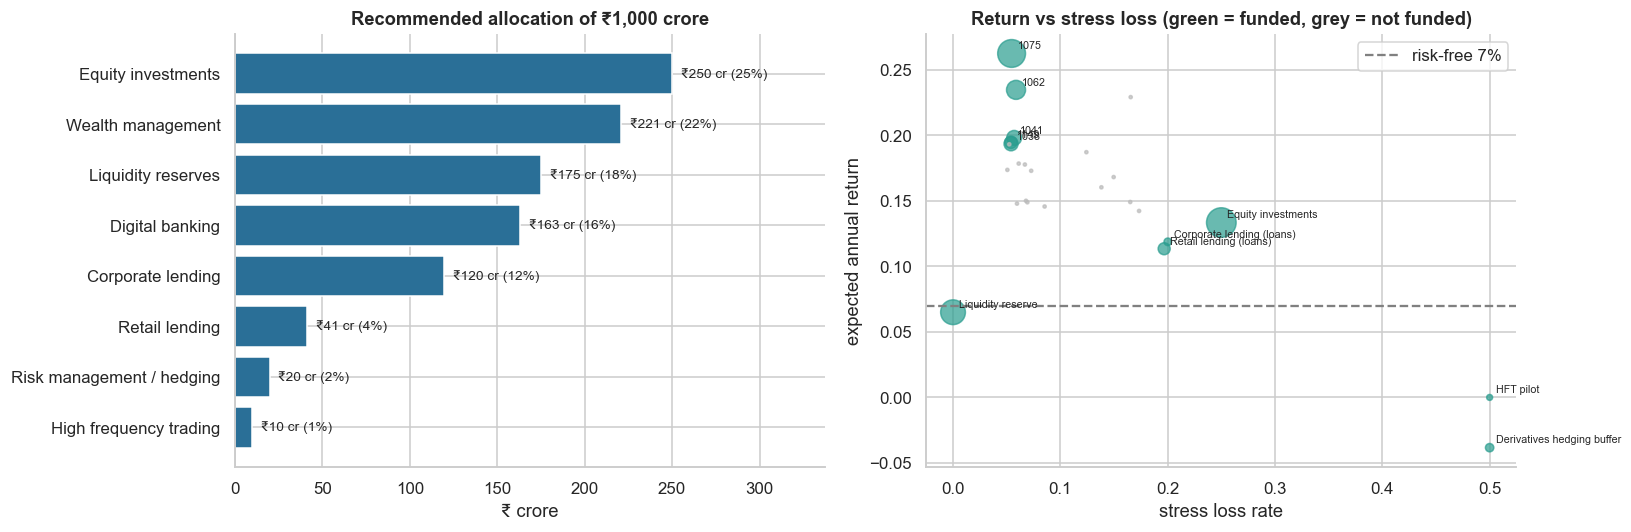

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
b = board.drop('TOTAL')
ax[0].barh(b.index[::-1], b['₹ crore'][::-1], color='#2a6f97')
for i, (v, s) in enumerate(zip(b['₹ crore'][::-1], b.Share[::-1])):
    ax[0].text(v + 5, i, f'₹{v:.0f} cr ({s:.0%})', va='center', fontsize=9)
ax[0].set(title='Recommended allocation of ₹1,000 crore', xlabel='₹ crore'); ax[0].set_xlim(0, b['₹ crore'].max() * 1.35)
pts = pd.concat([fund.assign(name=fund.Initiative_ID.astype(str), alloc=np.where(fund.Initiative_ID.isin(projects.Initiative_ID), fund.Initial_Investment, 0))
                 [['name', 'Return', 'Stress_Loss', 'alloc']].rename(columns={'Stress_Loss': 'Stress loss'}),
                 cont.assign(name=cont.index, alloc=x.reindex(cont.index).values)[['name', 'Return', 'Stress loss', 'alloc']]])
ax[1].scatter(pts['Stress loss'], pts.Return, s=np.maximum(pts.alloc, 3) * 1.5, c=np.where(pts.alloc > 0, '#2a9d8f', '#bbbbbb'), alpha=0.7)
for _, p in pts[pts.alloc > 0].iterrows():
    ax[1].annotate(p['name'], (p['Stress loss'], p.Return), fontsize=7, xytext=(4, 3), textcoords='offset points')
ax[1].axhline(RF, ls='--', c='grey', label='risk-free 7%')
ax[1].set(title='Return vs stress loss (green = funded, grey = not funded)', xlabel='stress loss rate', ylabel='expected annual return'); ax[1].legend()
plt.tight_layout(); savefig('allocation'); plt.show()

## 5. Is this allocation better than simple alternatives?
Benefit of choosing the optimised, limit-respecting allocation over:
- **All in liquid assets** (no business risk at all),
- **Equal split**: ₹125 cr per Board category (initiatives taken in PI order within each category),
- **Return-chasing**: rank by raw return only, with every risk-appetite limit removed (only capacity limits).

`Meets risk appetite` checks **every** limit, not only the stress loss.

In [13]:
def stats_of(x_, fund_pick):
    """Expected return, stress loss and limit checks for an allocation given as continuous ₹ + funded projects."""
    xc = x_.reindex(cont.index).fillna(0)
    ret = (xc * cont.Return).sum() + (fund_pick.Return * fund_pick.Initial_Investment).sum()
    loss = (xc * cont['Stress loss']).sum() + (fund_pick.Stress_Loss * fund_pick.Initial_Investment).sum()
    cat = pd.concat([xc.groupby(cont['Board category']).sum(), fund_pick.groupby('Board category').Initial_Investment.sum()]).groupby(level=0).sum()
    ok = (loss <= LIMITS['stress_max'] + 1e-6 and fund_pick.Initial_Investment.sum() <= LIMITS['initiatives_max'] + 1e-6
          and xc['Liquidity reserve'] >= LIMITS['reserve_min'] - 1e-6 and xc['Equity investments'] <= LIMITS['equity_max'] + 1e-6
          and cat.drop('Liquidity reserves', errors='ignore').max() <= LIMITS['category_max'] + 1e-6)
    return {'Expected return ₹ cr/yr': ret, 'Expected return %': ret / TOTAL, 'Stress loss ₹ cr': loss,
            'Stress loss % of capital': loss / TOTAL, 'Return ÷ stress loss': ret / loss if loss else np.nan,
            'Liquidity reserve ₹ cr': xc['Liquidity reserve'], 'Initiatives ₹ cr': fund_pick.Initial_Investment.sum(),
            'Meets risk appetite': ok}

def equal_split():
    """₹125 cr per Board category; initiatives by PI while they fit; continuous lines up to capacity; rest liquid."""
    per = TOTAL / 8
    xc = pd.Series(0.0, index=cont.index); picks = []
    for cat in ['Wealth management', 'Digital banking', 'Corporate lending', 'Retail lending', 'Equity investments',
                'High frequency trading', 'Risk management / hedging', 'Liquidity reserves']:
        left = per
        for _, p in fund[fund['Board category'] == cat].sort_values('PI', ascending=False).iterrows():
            if p.Initial_Investment <= left: picks.append(p); left -= p.Initial_Investment
        for n in cont.index[cont['Board category'] == cat]:
            add = min(left, cont.loc[n, 'Max'] - xc[n]); xc[n] += add; left -= add
        xc['Liquidity reserve'] += left
    return xc, pd.DataFrame(picks) if picks else fund.iloc[:0]

all_liquid = pd.Series(0.0, index=cont.index); all_liquid['Liquidity reserve'] = TOTAL
x_eq, f_eq = equal_split()
loose = {'initiatives_max': TOTAL, 'stress_max': TOTAL, 'category_max': TOTAL, 'reserve_min': 0.0, 'equity_max': TOTAL}
x_nl, f_nl = optimise(cont=cont.assign(Min=np.where(cont.index.isin(['HFT pilot', 'Derivatives hedging buffer']), 0.0, cont.Min)),
                      limits=loose, rank_by='return')                  # highest raw return first, no risk limits
alts = pd.DataFrame({'Recommended (limits applied)': stats_of(x, chosen_fund), 'Equal split': stats_of(x_eq, f_eq),
                     'All in liquid assets': stats_of(all_liquid, fund.iloc[:0]),
                     'Return-chasing (no limits)': stats_of(x_nl, f_nl)}).T
compare_models(alts, 'Expected return ₹ cr/yr', chosen='Recommended (limits applied)', baseline='All in liquid assets',
               extra=['Expected return %', 'Stress loss % of capital', 'Liquidity reserve ₹ cr', 'Initiatives ₹ cr', 'Meets risk appetite']).round(3)

,Rank,Expected return ₹ cr/yr,Expected return %,Stress loss % of capital,Liquidity reserve ₹ cr,Initiatives ₹ cr,Meets risk appetite,Gain vs baseline,Gap to best,Chosen
Return-chasing (no limits),1,219.702766,0.219703,0.084734,0.0,970.93,False,154.702766,0.0,
Recommended (limits applied),2,164.698996,0.164699,0.115994,175.0,487.33,True,99.698996,55.00377,✔
Equal split,3,123.318962,0.123319,0.081817,410.226912,372.55,True,58.318962,96.383804,
All in liquid assets,4,65.0,0.065,0.0,1000.0,0.0,True,0.0,154.702766,


**Reading.** The recommended allocation earns far more than parking the money in liquid assets and more than an equal
split, while meeting every limit. Return-chasing earns more only by putting almost everything into model-ranked
initiatives with **no liquidity reserve and no hedging buffer**. It fails the risk appetite, and its return depends
entirely on the weakest model in the project (initiative success, AUC 0.63) and on the 5-year-life assumption.

## 6. Sensitivity: does the recommendation survive if key assumptions are wrong?

In [14]:
def run(name, fund_=fund, cont_=cont, limits=LIMITS):
    """Re-optimise under changed assumptions; return ₹ by Board category and summary statistics."""
    x_, f_ = optimise(fund_, cont_, limits)
    by = pd.concat([x_.reindex(cont_.index).fillna(0).groupby(cont_['Board category']).sum(),
                    f_.groupby('Board category').Initial_Investment.sum()]).groupby(level=0).sum()
    ret = (x_.reindex(cont_.index).fillna(0) * cont_.Return).sum() + (f_.Return * f_.Initial_Investment).sum()
    loss = (x_.reindex(cont_.index).fillna(0) * cont_['Stress loss']).sum() + (f_.Stress_Loss * f_.Initial_Investment).sum()
    return name, by, {'Expected return %': ret / TOTAL, 'Stress loss % of capital': loss / TOTAL, 'Projects funded': len(f_)}

shift = lambda d, col, v, mask=None: d.assign(**{col: d[col] + (v if mask is None else np.where(mask, v, 0))})
scens = [run('Base'),
         run('Initiatives earn 10 pts less (3-year view)', fund_=shift(fund, 'Return', -0.10)),
         run('Equity return −5 pts', cont_=shift(cont, 'Return', -0.05, cont.index == 'Equity investments')),
         run('Credit stress: lending return −4 pts', cont_=shift(cont, 'Return', -0.04, cont.index.str.contains('loans'))),
         run('Severe liquidity reserve', limits={**LIMITS, 'reserve_min': liq['reserve_cr'] + liq['severe_extra_cr']}),
         run('Tighter appetite: stress ≤ 10%', limits={**LIMITS, 'stress_max': 0.10 * TOTAL})]
sens_alloc = pd.DataFrame({n: by for n, by, _ in scens}).fillna(0).round(0)
sens_stats = pd.DataFrame({n: s for n, _, s in scens}).T
sens_alloc

,Base,Initiatives earn 10 pts less (3-year view),Equity return −5 pts,Credit stress: lending return −4 pts,Severe liquidity reserve,Tighter appetite: stress ≤ 10%
Board category,,,,,,
Corporate lending,120.0,120.0,120.0,120.0,103.0,103.0
Digital banking,163.0,163.0,163.0,163.0,163.0,163.0
Equity investments,250.0,250.0,245.0,250.0,224.0,232.0
High frequency trading,10.0,10.0,10.0,10.0,10.0,10.0
Liquidity reserves,175.0,175.0,175.0,175.0,259.0,251.0
Retail lending,41.0,41.0,46.0,41.0,0.0,0.0
Risk management / hedging,20.0,20.0,20.0,20.0,20.0,20.0
Wealth management,221.0,221.0,221.0,221.0,221.0,221.0


In [15]:
sens_stats.round(3)

,Expected return %,Stress loss % of capital,Projects funded
Base,0.165,0.116,5.0
Initiatives earn 10 pts less (3-year view),0.116,0.116,5.0
Equity return −5 pts,0.152,0.116,5.0
Credit stress: lending return −4 pts,0.162,0.116,5.0
Severe liquidity reserve,0.160,0.098,5.0
Tighter appetite: stress ≤ 10%,0.161,0.100,5.0


**Reading the sensitivity.** The **core** of the recommendation (liquidity reserve, hedging buffer, the best wealth,
digital and corporate initiatives, a diversified equity sleeve) appears in every scenario. What moves is mainly the
split between equity and the marginal initiatives. A tighter appetite cuts equity first, because it carries the
largest stress loss per rupee; a severe liquidity requirement is funded mainly from equity.

## 7. Combined crisis test (everything goes wrong in the same year)
Equity market −25%; initiatives' success odds −10 points; credit PD ×1.5 and LGD 50%; options crash; HFT pilot loses
half; funding freeze + 10% deposit run (covered by the reserve).

In [16]:
crisis_loss = final['Stress loss ₹ cr'].sum()                                             # all stress losses at once
expected_income = final['Return ₹ cr/yr'].sum()                                           # one year of expected earnings
shortfall_B = liq['reserve_cr']                                                           # scenario-B need beyond today's buffer
crisis = pd.Series({'Expected annual return (₹ cr)': expected_income,
                    'Combined stress loss (₹ cr)': crisis_loss,
                    'Net result in crisis year (₹ cr)': expected_income - crisis_loss,
                    'Capital after a crisis year (₹ cr)': TOTAL + expected_income - crisis_loss,
                    'Liquidity reserve ÷ scenario-B shortfall': x['Liquidity reserve'] / shortfall_B})
crisis.round(2).to_frame('combined crisis')

,combined crisis
Expected annual return (₹ cr),164.70
Combined stress loss (₹ cr),115.99
Net result in crisis year (₹ cr),48.70
Capital after a crisis year (₹ cr),1048.70
Liquidity reserve ÷ scenario-B shortfall,1.00


**Reading.** Even if every stress happens in the same year, the stress losses are roughly covered by one year of
expected earnings, so the ₹1,000 crore is broadly preserved, and the liquidity reserve covers the 30-day stressed
funding need. This is the test a Board should require before approving any allocation.

## 8. How the modules feed the decision (integration map)

In [17]:
cr_ = R['credit']; fr = R['fraud']; ch = R['churn']; po = R['portfolio']; hf = R['hft']; op = R['options']
chain = pd.DataFrame([
    ['Strategic initiatives (M1)', 'P(success): 3-driver logistic, AUC 0.63', 'NPV, risk-adjusted E[NPV], PI', 'success odds −10 pts; 3-year life', f"Fund {len(projects)} projects, ₹{x[x.index.str.contains('initiatives')].sum():.0f} cr"],
    ['Credit (M2)', f"PD: logistic, AUC {cr_['model']['test_roc_auc']:.2f}", 'ECL = PD × LGD × EAD; ROE', 'PD ×1.5 → ECL 4.2% > 3% appetite', f"Approve PD < {cr_['assumptions']['approve_pd_below']}; lend ₹{x[x.index.str.contains('loans')].sum():.0f} cr capital"],
    ['Fraud (M3)', f"{fr['model']['chosen']}, test PR-AUC {fr['model']['test'][fr['model']['chosen']]['PR-AUC']:.3f}", 'cost = 10,000 × missed + 500 × false alarms', 'cost and drift stress: saving 20–50%', f"Deploy at cost-optimal threshold: {fr['saving_share']:.0%} saving (opex, not capital)"],
    ['Churn & CLV (M4)', 'churn: no signal (AUC ≈ 0.5)', 'lifetime CLV, EVaR', 'save-rate / cost grid', f"Call top 1,000 by EVaR: net ₹{ch['campaign']['net_inr'] / 1e5:.0f} lakh (opex)"],
    ['Equity & portfolio (M5–6)', 'Ridge IC 0.056 (not significant)', 'Sharpe, VaR, drawdown', 'crisis VaR ≈ 30%/month; −25% shock', f"Equal-weight sleeve ₹{x['Equity investments']:.0f} cr; ML tilt on watch"],
    ['HFT (M7)', 'order-book model, macro-F1 0.44', 'net bp per trade after costs', 'costs ×2 or 1-event delay → loss', f"₹{x['HFT pilot']:.0f} cr pilot with stop-loss; use for execution"],
    ['Derivatives (M8)', 'ML does not beat Black-Scholes', 'Greeks, VaR, hedge cost', 'crash and vol spike', f"Hedging buffer ₹{x['Derivatives hedging buffer']:.0f} cr; vega limits"],
    ['Liquidity (extra)', 'gap forecast: Ridge ≈ 20-day avg', '30-day stressed need', 'freeze + 10% deposit run', f"Reserve ₹{x['Liquidity reserve']:.0f} cr"],
], columns=['Line / module', 'ML prediction', 'Financial metric', 'Risk assessment', 'Business decision'])
chain

,Line / module,ML prediction,Financial metric,Risk assessment,Business decision
0,Strategic initiatives (M1),"P(success): 3-driver logistic, AUC 0.63","NPV, risk-adjusted E[NPV], PI",success odds −10 pts; 3-year life,"Fund 5 projects, ₹487 cr"
1,Credit (M2),"PD: logistic, AUC 0.75",ECL = PD × LGD × EAD; ROE,PD ×1.5 → ECL 4.2% > 3% appetite,Approve PD < 0.11; lend ₹58 cr capital
2,Fraud (M3),"Random forest, test PR-AUC 0.142","cost = 10,000 × missed + 500 × false alarms",cost and drift stress: saving 20–50%,Deploy at cost-optimal threshold: 38% saving (...
3,Churn & CLV (M4),churn: no signal (AUC ≈ 0.5),"lifetime CLV, EVaR",save-rate / cost grid,"Call top 1,000 by EVaR: net ₹23 lakh (opex)"
4,Equity & portfolio (M5–6),Ridge IC 0.056 (not significant),"Sharpe, VaR, drawdown",crisis VaR ≈ 30%/month; −25% shock,Equal-weight sleeve ₹250 cr; ML tilt on watch
5,HFT (M7),"order-book model, macro-F1 0.44",net bp per trade after costs,costs ×2 or 1-event delay → loss,₹10 cr pilot with stop-loss; use for execution
6,Derivatives (M8),ML does not beat Black-Scholes,"Greeks, VaR, hedge cost",crash and vol spike,Hedging buffer ₹20 cr; vega limits
7,Liquidity (extra),gap forecast: Ridge ≈ 20-day avg,30-day stressed need,freeze + 10% deposit run,Reserve ₹175 cr


## 9. Controls and governance
| Risk | Control | Trigger / limit | Owner |
|---|---|---|---|
| Credit | approve only PD < 0.11 and positive value; reprice the review queue | portfolio ECL > 3% of approved book | CRO / credit committee |
| Initiatives | stage-gate funding (tranches); re-score P(success) yearly | project behind plan 2 quarters → stop next tranche | CFO |
| Market (equity) | equal-weight sleeve, 25% cap, quarterly rebalance | drawdown > 10% → cut sleeve by half | CIO |
| Derivatives | delta hedge daily; vega limit | book loss > ₹0.5 cr per volatility point → buy options back as protection | Head of derivatives |
| HFT | ₹10 cr pilot, kill switch | daily loss > ₹0.5 cr or cumulative > ₹2 cr → stop | Head of trading |
| Liquidity | reserve ≥ scenario-B need | coverage < 110% → stop wholesale-funded growth | Treasurer / ALCO |
| Fraud | cost-optimal threshold; monthly PR-AUC check | PR-AUC falls 30% or alert volume doubles → retrain | Head of fraud ops |
| Model risk | model inventory, annual independent validation, SHAP explanations kept on file | any drift alarm → revalidate before use | Model risk committee |

In [18]:
res = {'module': 'allocation',
       'limits': {**LIMITS, 'single_line_max': 0.30 * TOTAL, 'equity_max': 0.25 * TOTAL},
       'lines': lines.round(4).to_dict(orient='index'),
       'allocation_lines_cr': x.round(2).to_dict(), 'allocation_board': board.round(4).to_dict(orient='index'),
       'funded_initiatives': projects.Initiative_ID.tolist(),
       'alternatives': alts.round(4).to_dict(orient='index'),
       'sensitivity_allocation': sens_alloc.to_dict(), 'sensitivity_stats': sens_stats.round(4).to_dict(orient='index'),
       'crisis': crisis.round(3).to_dict()}
save_result('allocation', res)
final.to_csv(RES / 'final_allocation_lines.csv'); board.to_csv(RES / 'final_allocation_board.csv')
projects.to_csv(RES / 'funded_initiatives.csv', index=False)

saved results/Module_09_Integrated_Allocation/allocation.json


## 10. Final conclusion for the Board
### The answer in one paragraph
Deploy the ₹1,000 crore in three layers. **Grow** where the evidence is strongest: five high-value initiatives
(₹487 cr) and a small, well-priced lending book. **Earn steadily** through a diversified equity sleeve (₹250 cr).
**Protect** the group with a liquidity reserve, a derivatives hedging buffer and a tightly capped HFT pilot
(₹205 cr). Expected return is about **16.5% a year (₹165 cr)**. The combined stress loss (₹116 cr, 11.6%) is inside the
15% risk appetite, and even if every stress hits in the same year the group still earns about ₹49 cr.

### Recommended allocation
| Board category | ₹ crore | Share | What it funds | Evidence |
|---|---|---|---|---|
| Equity investments | 250 | 25% | equal-weight 15-stock sleeve | M5–6: ML picks not significant; equal-weight best Sharpe (1.30) |
| Wealth management | 221 | 22% | initiative 1075 (Low risk, P = 0.92, PI 0.71) | M1: highest value per rupee |
| Liquidity reserves | 175 | 18% | cash + government securities | Extra: survive funding freeze + 10% deposit run for 30 days |
| Digital banking | 163 | 16% | initiatives 1041, 1149, 1038 (Low risk, P ≈ 0.91) | M1; supported by M3 fraud control and M4 retention |
| Corporate lending | 120 | 12% | initiative 1062 (₹103 cr) + ₹16 cr capital for approved corporate loans | M1 + M2 |
| Retail lending | 41 | 4% | capital for ≈ ₹330 cr of approved retail loans (PD < 0.11) | M2: thin margin, strict approval rule |
| Risk management / hedging | 20 | 2% | options hedging buffer | M8: delta hedge cuts VaR 80%; volatility spike still costs ₹5.4 cr |
| High frequency trading | 10 | 1% | pilot with kill switch, mainly execution | M7: edge vanishes with costs × 2 or latency |
| **Total** | **1,000** | 100% | expected return ≈ 16.5% a year | stress loss ₹116 cr (limit ₹150 cr) |

### What risks NovaFin takes, and how they are controlled
- **Execution risk on initiatives** (₹487 cr): only Low-risk projects with P(success) ≥ 0.90; stage-gated tranches;
  a 3-year-payback view would cut returns by about 5 points but leave the choice unchanged.
- **Market risk** (₹250 cr equity): equal-weight, 25% cap, drawdown trigger at −10%; crisis loss ≈ ₹63 cr.
- **Credit risk**: lend only to PD < 0.11 with positive expected value; ECL ≤ 3% of the approved book; reprice the review queue.
- **Liquidity risk**: the reserve covers the stressed 30-day need; triggers on coverage and wholesale-funding falls.
- **Derivatives risk**: daily delta hedge, a limit on volatility exposure (vega) and the ₹20 cr buffer.
- **Model risk**: every model has a named owner, monitoring metric and retraining trigger (table above).

### Where ML paid off, and where it did not (honest scorecard)
| Module | ML verdict | Business use |
|---|---|---|
| Credit (M2) | **Useful**: AUC 0.75, calibrated PDs | approve / review / reject with ECL control |
| Fraud (M3) | **Useful**: PR-AUC 6× random | **38% lower fraud cost** at the cost-optimal threshold (no capital needed) |
| Initiatives (M1) | **Weak but usable**: AUC 0.63 | risk adjustment on top of NPV |
| HFT (M7) | **Strong signal, fragile profit** | execution timing, not proprietary trading |
| Churn (M4) | **No signal** (AUC ≈ 0.5) | value-led targeting instead (net ₹23 lakh on 1,000 calls) |
| Equity (M5–6) | **Not significant** (IC 0.06) | stay diversified; ML tilt on watch |
| Options (M8) | **Does not beat Black-Scholes** | keep the theory for pricing and hedging; ML needs a real volatility surface |

The integrated lesson: **ML adds value where there is real signal and a clear cost function (credit, fraud,
execution)**. Where the signal is absent, the disciplined choice is the simpler model or the theory, and the
capital decision rests on finance (NPV, ECL, diversification, stress) rather than on model scores.

### Limitations
All data are synthetic. Several unit and behavioural assumptions are stated in the notebooks: initiatives in ₹ crore,
liquidity in ₹ lakh, a 5-year project life, a 12.5% capital ratio and 4 lending cycles a year, and run-off rates.
Returns are point estimates from short samples; the sensitivity and crisis tests show the recommendation is robust to
the main ones.

### Next steps (first 90 days)
1. Approve tranche 1 of the five initiatives; set up stage-gate KPIs.
2. Put the fraud model live at the cost-optimal threshold; start the 1,000-customer RM campaign.
3. Fund the liquidity reserve and the hedging buffer before any growth capital is drawn.
4. Launch the equity sleeve; run the ML tilt as a paper portfolio.
5. Model governance: inventory, independent validation and monitoring dashboards for every model above.